# Project 3: Recycling Collection Share Visualizations

## Notebook Purpose

The purpose of this notebook is to create visualizations that communicate the findings of our Project 3 analysis of dry recycling collection share across New York City's 59 community districts. Using the prepared district-level dataset and official NYC geographic boundaries, this notebook will produce figures that help illustrate differences in recycling performance, examine relationships between community characteristics and recycling collection share, and identify districts that perform below their income-based expectations.

The visualizations developed in this notebook will support the findings presented in the final project report and help communicate the results in a clear and accessible way. Each figure will focus on a specific research finding and will be designed to highlight meaningful patterns without overstating relationships or implying causation.

The notebook will focus on the following visualizations:

1. **Geographic distribution:** Map dry recycling collection share across the 59 community districts.
2. **Borough comparison:** Compare recycling collection share across New York City's five boroughs.
3. **Income relationship:** Examine the association between median household income and recycling collection share.
4. **Performance gaps:** Identify districts with recycling collection shares below their income-based predictions.

All visualizations will use the team's prepared data and will be reviewed for accuracy, readability, and suitability for inclusion in the final report.

## Visualization 1: Geographic Distribution of Dry Recycling Collection Share Across NYC Community Districts (2025)

This visualization will use a choropleth map to show how dry recycling collection share varies geographically across NYC's 59 community districts in 2025. The map will combine the district level recycling data with official NYC community district boundary data. Each district will be shaded according to its 2025 dry recycling collection share, allowing geographic patterns and differences across the city to be identified.

In [2]:
# Import libraries
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Load prepared 2025 district-level data
district_data = pd.read_csv("district_features_2025-Copy1.csv")

# Load official NYC community district boundaries
boundary_url = (
    "https://data.cityofnewyork.us/api/v3/views/"
    "5crt-au7u/query.geojson?accessType=DOWNLOAD"
)

district_boundaries = gpd.read_file(boundary_url)

# Inspect both datasets
print("District data shape:", district_data.shape)
print("Boundary data shape:", district_boundaries.shape)

print("\nDistrict data columns:")
print(district_data.columns.tolist())

print("\nBoundary data columns:")
print(district_boundaries.columns.tolist())

District data shape: (59, 15)
Boundary data shape: (71, 8)

District data columns:
['boro_cd', 'borough', 'recycling_share_2025_pct', 'high_risk', 'lep_pct', 'rent_stab_share', 'nycha_share', 'permits_per_1k', 'log_income', 'log_income_furman', 'share_2024', 'share_2019', 'hh_income', 'furman_income', 'income_flagged']

Boundary data columns:
[':id', ':version', ':created_at', ':updated_at', 'boro_cd', 'shape_leng', 'shape_area', 'geometry']


In [3]:
print("District data type:", district_data["boro_cd"].dtype)
print("Boundary data type:", district_boundaries["boro_cd"].dtype)

print("\nDistrict examples:")
print(district_data["boro_cd"].head())

print("\nBoundary examples:")
print(district_boundaries["boro_cd"].head())

District data type: int64
Boundary data type: object

District examples:
0    101
1    102
2    103
3    104
4    105
Name: boro_cd, dtype: int64

Boundary examples:
0    226
1    313
2    105
3    110
4    164
Name: boro_cd, dtype: object


In [4]:
# Convert boundary district IDs to integers
district_boundaries["boro_cd"] = district_boundaries["boro_cd"].astype(int)

# Keep only boundaries that match our 59 district records
district_boundaries_59 = district_boundaries[
    district_boundaries["boro_cd"].isin(district_data["boro_cd"])
].copy()

# Check the result
print("Filtered boundary data shape:", district_boundaries_59.shape)
print("Unique community districts:", district_boundaries_59["boro_cd"].nunique())

Filtered boundary data shape: (59, 8)
Unique community districts: 59


In [5]:
# Join recycling data with the geographic boundaries
recycling_map = district_boundaries_59.merge(
    district_data,
    on="boro_cd",
    how="inner"
)

# Check the joined dataset
print("Joined data shape:", recycling_map.shape)
print("Unique community districts:", recycling_map["boro_cd"].nunique())
print("Missing geometries:", recycling_map.geometry.isna().sum())
print("Missing recycling shares:", recycling_map["recycling_share_2025_pct"].isna().sum())

Joined data shape: (59, 22)
Unique community districts: 59
Missing geometries: 0
Missing recycling shares: 0


In [6]:
print("Current CRS:", recycling_map.crs)

Current CRS: EPSG:4326


In [7]:
# Reproject to New York State Plane coordinates
recycling_map = recycling_map.to_crs(epsg=2263)

# Confirm the new CRS
print("Updated CRS:", recycling_map.crs)

Updated CRS: EPSG:2263


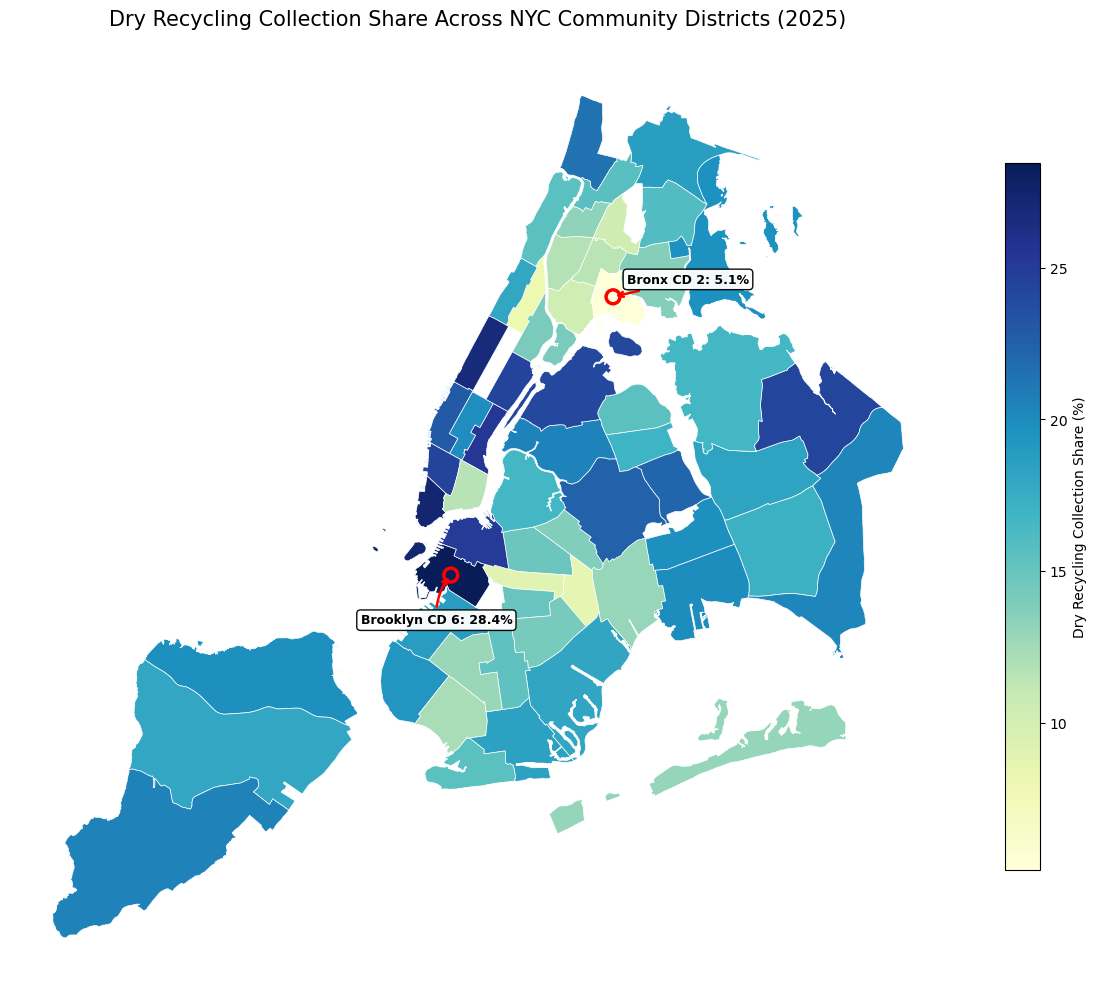

In [19]:

fig, ax = plt.subplots(1, 1, figsize=(12, 10))

# Plot all 59 community districts
recycling_map.plot(
    column="recycling_share_2025_pct",
    cmap="YlGnBu",
    linewidth=0.5,
    edgecolor="white",
    legend=True,
    legend_kwds={
        "label": "Dry Recycling Collection Share (%)",
        "shrink": 0.75
    },
    ax=ax
)

# Highlight the two districts
for _, district in recycling_map[
    recycling_map["boro_cd"].isin([202, 306])
].iterrows():

    point = district["label_point"]

    # Add a hollow red circle at the district location
    ax.scatter(
        point.x,
        point.y,
        s=100,
        facecolors="none",
        edgecolors="red",
        linewidths=2.5,
        zorder=5
    )

    if district["boro_cd"] == 202:
        label = f"Bronx CD 2: {district['recycling_share_2025_pct']:.1f}%"

        ax.annotate(
            label,
            xy=(point.x, point.y),
            xytext=(10, 10),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.95),
            arrowprops=dict(
                arrowstyle="->",
                color="red",
                linewidth=1.8
            )
        )

    elif district["boro_cd"] == 306:
        label = f"Brooklyn CD 6: {district['recycling_share_2025_pct']:.1f}%"

        ax.annotate(
            label,
            xy=(point.x, point.y),
            xytext=(-65, -35),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.95),
            arrowprops=dict(
                arrowstyle="->",
                color="red",
                linewidth=1.8,
                connectionstyle="arc3,rad=-0.2"
            )
        )

# Title and formatting
ax.set_title(
    "Dry Recycling Collection Share Across NYC Community Districts (2025)",
    fontsize=15,
    pad=20
)

ax.set_axis_off()

plt.tight_layout()

# Save map at high resolution for the report
plt.savefig(
    "fig1_nyc_dry_recycling_share_2025.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [17]:
# Create representative points inside each district
recycling_map["label_point"] = recycling_map.geometry.representative_point()

# Display the locations and values for the two districts
recycling_map.loc[
    recycling_map["boro_cd"].isin([202, 306]),
    ["boro_cd", "recycling_share_2025_pct", "label_point"]
]

,boro_cd,recycling_share_2025_pct,label_point
9,306,28.448083,POINT (985347.827 185875.11)
55,202,5.141114,POINT (1014749.548 236307.174)


## Visualization 2: Borough-Level Comparison of Dry Recycling Collection Share (2025)

This visualization compares dry recycling collection share across NYC's five boroughs in 2025. The figure will compare borough-level recycling collection shares using the annual district data. It will provide a higher-level view  of geographic differences and complement the previous visualization, which examined all 59 community districts individually. 

In [23]:
print(district_data.columns.tolist())

['boro_cd', 'borough', 'recycling_share_2025_pct', 'high_risk', 'lep_pct', 'rent_stab_share', 'nycha_share', 'permits_per_1k', 'log_income', 'log_income_furman', 'share_2024', 'share_2019', 'hh_income', 'furman_income', 'income_flagged']


In [24]:
district_data.head()

,boro_cd,borough,recycling_share_2025_pct,high_risk,lep_pct,rent_stab_share,nycha_share,permits_per_1k,log_income,log_income_furman,share_2024,share_2019,hh_income,furman_income,income_flagged
0,101,Manhattan,27.297354,0,5.167437,25.93,0.0,0.032799,12.206073,12.249946,27.339894,30.096107,200000.000000,208970.0,True
1,102,Manhattan,24.382031,0,5.166859,30.01,0.0,1.977426,12.000064,12.249946,23.426727,26.497418,162765.263563,208970.0,False
2,103,Manhattan,11.607429,1,25.665587,29.47,22.1,1.169791,10.993569,10.896184,11.483291,12.770003,59490.329668,53970.0,False
3,104,Manhattan,22.879639,0,8.497264,44.69,4.0,0.184028,11.669604,11.729970,22.210130,25.151329,116961.970777,124240.0,False
4,105,Manhattan,19.831199,0,8.497668,37.95,0.0,2.844813,12.061411,11.729970,19.969670,21.847275,173062.944330,124240.0,False


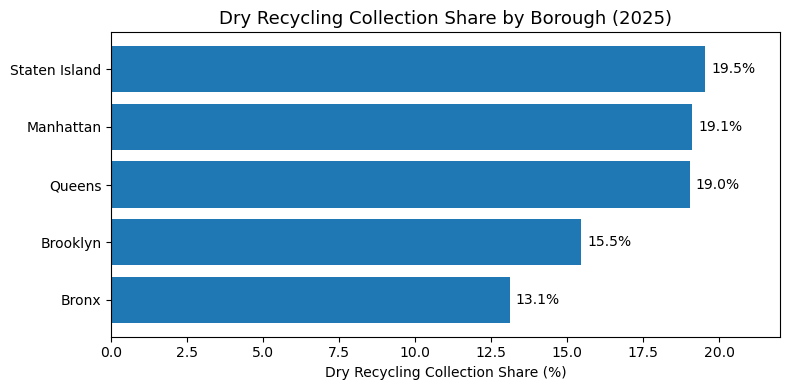

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the tonnage-weighted borough summary
borough_summary = pd.read_csv(
    "rq1_borough_2025_TONNAGE_WEIGHTED_CONTEXT_ONLY.csv"
)

# Sort boroughs from highest to lowest
borough_summary = borough_summary.sort_values(
    "dry_recycling_share_2025_pct",
    ascending=False
)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.barh(
    borough_summary["borough"],
    borough_summary["dry_recycling_share_2025_pct"]
)

# Place highest borough at the top
ax.invert_yaxis()

# Add percentage labels
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center"
    )

# Format chart
ax.set_title(
    "Dry Recycling Collection Share by Borough (2025)",
    fontsize=13
)
ax.set_xlabel("Dry Recycling Collection Share (%)")
ax.set_ylabel("")
ax.set_xlim(0, 22)

plt.tight_layout()

# Save figure
plt.savefig(
    "fig2_borough_share_2025.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## Visualization 3: Median Household Income vs. Dry Recycling Collection Share (2025)

This visualization examines the relationship between median household income and dry recycling collection share across NYC's 59 community districts. A scatterplot will display this relationship for each community district. 

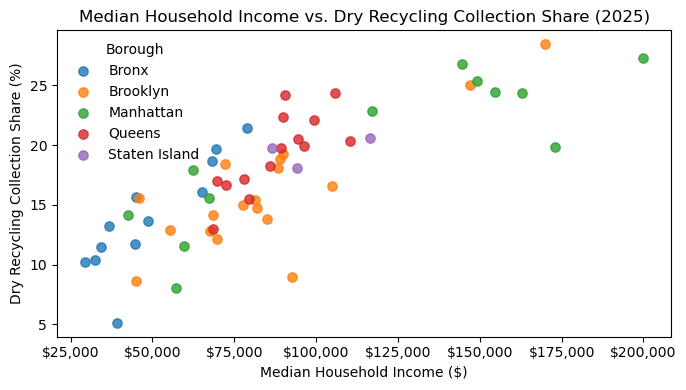

In [28]:
# Visualization 3: Median Household Income vs. Dry Recycling Collection Share

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))

# Plot each borough separately
for borough in sorted(district_data["borough"].unique()):
    subset = district_data[district_data["borough"] == borough]

    ax.scatter(
        subset["hh_income"],
        subset["recycling_share_2025_pct"],
        label=borough,
        alpha=0.8,
        s=45
    )

# Chart formatting
ax.set_title(
    "Median Household Income vs. Dry Recycling Collection Share (2025)"
)

ax.set_xlabel("Median Household Income ($)")
ax.set_ylabel("Dry Recycling Collection Share (%)")

ax.legend(title="Borough", frameon=False)

# Format income axis
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

plt.tight_layout()

# Save figure
plt.savefig(
    "fig3_income_vs_recycling.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## Visualization 4: Districts Performing Below Income-Based Expectations (2025)

This visualization identifies community districts where actual dry recycling collection share falls below the level predicted by the income-based regression model. A horizonal bar chart will display the districts with the largest negative differences. 

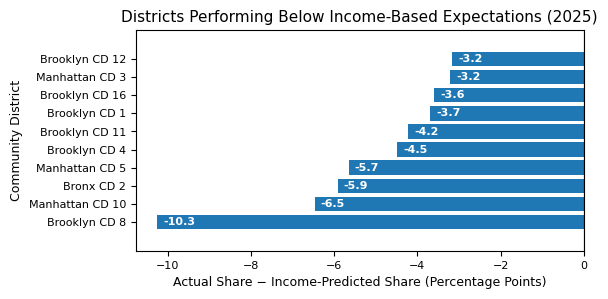

In [33]:
# Visualization 4: Districts Performing Below Income-Based Expectations

import pandas as pd
import matplotlib.pyplot as plt

# Load income-gap results
gap_data = pd.read_csv("rq2_gap_vs_income copy.csv")

# Select 10 districts with the largest negative gaps
gap_plot = gap_data.nsmallest(10, "gap_vs_income").copy()

# Create district labels
gap_plot["district"] = (
    gap_plot["borough"] + " CD " +
    (gap_plot["boro_cd"] % 100).astype(str)
)

# Sort for horizontal bar chart
gap_plot = gap_plot.sort_values("gap_vs_income")

# Create figure
fig, ax = plt.subplots(figsize=(7, 3.5))

bars = ax.barh(
    gap_plot["district"],
    gap_plot["gap_vs_income"]
)

# Add value labels INSIDE the negative bars
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}",
        ha="left",
        va="center",
        color="white",
        fontsize=8,
        fontweight="bold"
    )

# Add zero reference line
ax.axvline(0, color="black", linewidth=0.8)

# Format chart
ax.set_title(
    "Districts Performing Below Income-Based Expectations (2025)",
    fontsize=11
)
ax.set_xlabel(
    "Actual Share − Income-Predicted Share (Percentage Points)",
    fontsize=9
)
ax.set_ylabel("Community District", fontsize=9)

ax.tick_params(axis="both", labelsize=8)

# Add room around the chart
ax.margins(y=0.12)
plt.subplots_adjust(left=0.34, bottom=0.22, top=0.85, right=0.98)

# Save figure
plt.savefig(
    "fig4_income_gap_districts.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()